In [109]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'

In [107]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
import numpy as np
from sklearn.metrics import silhouette_score


In [2]:
HomeownerModeling_df  = pd.read_csv("HomeownerDatasetForModeling_FinalCopy.csv")

In [3]:
HomeownerModeling_df.head()

,FREQUENCY,PERIOD BEGIN,PERIOD END,REGION NAME,PROPERTY TYPE,INCOME GROUP,DOWN PAYMENT PERCENT (%),INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),...,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,Season,Year-Month,Period Length (Days),affordable,Region Identifier
0,Monthly,2026-06-01,2026-06-30,Alabama,Single Family,Homeowner,3.5,90532.0,-1.49,31.52,...,0.4057,0.0287,-0.0276,0.0130,0.0832,Summer,2026-06,30,0.0,Southeast
1,Monthly,2026-05-01,2026-05-31,Alabama,Single Family,Homeowner,3.5,90652.0,-0.56,31.56,...,0.4212,0.0419,-0.0142,0.0269,0.0091,Spring,2026-05,31,0.0,Southeast
2,Monthly,2026-04-01,2026-04-30,Alabama,Single Family,Homeowner,3.5,88160.0,0.65,30.69,...,0.4302,0.0365,-0.0003,0.0413,0.0217,Spring,2026-04,30,0.0,Southeast
3,Monthly,2026-03-01,2026-03-31,Alabama,Single Family,Homeowner,3.5,86472.0,-1.26,30.11,...,0.4482,0.0405,-0.0133,0.0279,0.0641,Spring,2026-03,31,0.0,Southeast
4,Monthly,2026-02-01,2026-02-28,Alabama,Single Family,Homeowner,3.5,82901.0,-3.96,28.86,...,0.4824,0.0765,-0.0137,0.0274,0.0637,Winter,2026-02,28,1.0,Southeast


**Model 1 Classification of Affordability**


Target Variable: Affordable:

* 1 = Affordable
* 0 = Not Affordable

Predictor Variables:

* Down Payment %
* Month Name (One hot encode this to prep for modeling)
* Region Identifier
* Median Household Income ($)

* Median Sale Price ($)

In [5]:
#Subsetting the Homeowner Modeling Dataframe to a Model 1 Dataframe with variables of interest

#columns of interest
Model1_cols = ['affordable', 'DOWN PAYMENT PERCENT (%)', 'Month Name', 'Region Identifier', 'MEDIAN HOUSEHOLD INCOME ($)', 'MEDIAN SALE PRICE ($)']

#subsetting step:
Model1_df = HomeownerModeling_df[Model1_cols]

In [8]:
#making sure that model 1 cols of interest are only in subsetted model 1 dataframe
Model1_df.columns

Index(['affordable', 'DOWN PAYMENT PERCENT (%)', 'Month Name',
       'Region Identifier', 'MEDIAN HOUSEHOLD INCOME ($)',
       'MEDIAN SALE PRICE ($)'],
      dtype='object')

In [9]:
Model1_df.head()

,affordable,DOWN PAYMENT PERCENT (%),Month Name,Region Identifier,MEDIAN HOUSEHOLD INCOME ($),MEDIAN SALE PRICE ($)
0,0.0,3.5,June,Southeast,86165,303787.0
1,0.0,3.5,May,Southeast,86165,305490.0
2,0.0,3.5,April,Southeast,86165,299900.0
3,0.0,3.5,March,Southeast,86165,297976.0
4,1.0,3.5,February,Southeast,86165,288900.0


In [11]:
len(Model1_df)

42655

In [10]:
#examning NA value counts by column
Model1_df.isna().sum()

affordable                     340
DOWN PAYMENT PERCENT (%)         0
Month Name                       0
Region Identifier                0
MEDIAN HOUSEHOLD INCOME ($)      0
MEDIAN SALE PRICE ($)          380
dtype: int64

In [13]:
#Checking which rows have both affordable and MEDIAN SALE PRICE ($) missing:
print("Rows with both affordable and MEDIAN HOUSEHOLD INCOME ($) missing:")
((Model1_df['affordable'].isna()) & (Model1_df['MEDIAN SALE PRICE ($)'].isna())).sum()

Rows with both affordable and MEDIAN HOUSEHOLD INCOME ($) missing:


np.int64(340)

There are 340 rows with both 'affordable' and 'median sale price' missing. Affordable rows could be a subset of median sale price rows.

In [14]:
total_to_drop = ((Model1_df['affordable'].isna()) | (Model1_df['MEDIAN SALE PRICE ($)'].isna())).sum()
print("Total unique rows that would be dropped (union, not just overlap):", total_to_drop)

Total unique rows that would be dropped (union, not just overlap): 380


According to the NA analysis above, 340 rows have both 'affordable' and 'median sale price' missing.

The union of NA rows between 'affordable' and 'median sale price' is 380 rows - this tells us there are 40 rows with only 'median sale price missing'.

380 out of 42,655 rows have missing NA data. This is approximately 0.89% of the data that is dropped for this particular model.

In [21]:
#Cleaned1_df should have cleaned data with no rows missing - taking the first step of making the copy of the pandas dataset
CleanedModel1_df = Model1_df.copy()

In [22]:
CleanedModel1_df.isna().sum()

affordable                     340
DOWN PAYMENT PERCENT (%)         0
Month Name                       0
Region Identifier                0
MEDIAN HOUSEHOLD INCOME ($)      0
MEDIAN SALE PRICE ($)          380
dtype: int64

In [23]:
#Dropping NA values:
CleanedModel1_df = CleanedModel1_df.dropna(subset = ['affordable', 'MEDIAN SALE PRICE ($)'])

In [24]:
#checking that NA counts were dropped and NA counts are 0 for every variable
CleanedModel1_df.isna().sum()

affordable                     0
DOWN PAYMENT PERCENT (%)       0
Month Name                     0
Region Identifier              0
MEDIAN HOUSEHOLD INCOME ($)    0
MEDIAN SALE PRICE ($)          0
dtype: int64

In [25]:
CleanedModel1_df['DOWN PAYMENT PERCENT (%)'].dtype

dtype('float64')

In [31]:
CleanedModel1_df['Region Identifier'].unique()

array(['Southeast', 'Non-Contiguous States', 'Southwest', 'Mountain West',
       'Outside US', 'Northeast', 'Midwest', 'PNW'], dtype=object)

Now, identify categorical columns to one hot encode:

* Month Name
* Region Identifier

In [28]:
#intializing columns to one hot encode:
colsTo_OneHotEncode = ['Month Name', 'Region Identifier']

#one hot encoding the categorical variables, dropping first category to avoid multicollinearity:
ENCODEDCleanedModel1_df = pd.get_dummies(CleanedModel1_df, columns=colsTo_OneHotEncode,drop_first=True,dtype=int)

In [29]:
ENCODEDCleanedModel1_df.head()

,affordable,DOWN PAYMENT PERCENT (%),MEDIAN HOUSEHOLD INCOME ($),MEDIAN SALE PRICE ($),Month Name_August,Month Name_December,Month Name_February,Month Name_January,Month Name_July,Month Name_June,...,Month Name_November,Month Name_October,Month Name_September,Region Identifier_Mountain West,Region Identifier_Non-Contiguous States,Region Identifier_Northeast,Region Identifier_Outside US,Region Identifier_PNW,Region Identifier_Southeast,Region Identifier_Southwest
0,0.0,3.5,86165,303787.0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
1,0.0,3.5,86165,305490.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0.0,3.5,86165,299900.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,0.0,3.5,86165,297976.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,1.0,3.5,86165,288900.0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0


In [30]:
ENCODEDCleanedModel1_df.columns

Index(['affordable', 'DOWN PAYMENT PERCENT (%)', 'MEDIAN HOUSEHOLD INCOME ($)',
       'MEDIAN SALE PRICE ($)', 'Month Name_August', 'Month Name_December',
       'Month Name_February', 'Month Name_January', 'Month Name_July',
       'Month Name_June', 'Month Name_March', 'Month Name_May',
       'Month Name_November', 'Month Name_October', 'Month Name_September',
       'Region Identifier_Mountain West',
       'Region Identifier_Non-Contiguous States',
       'Region Identifier_Northeast', 'Region Identifier_Outside US',
       'Region Identifier_PNW', 'Region Identifier_Southeast',
       'Region Identifier_Southwest'],
      dtype='object')

Encoding Occurred:

* Month Name: April was excluded via drop_first = True
* Region Identifier: Midwest was excluded via drop_first = True

Checking for class imbalance between Affordable=1 and Affordable = 0 in Encoded Model 1 Dataframe

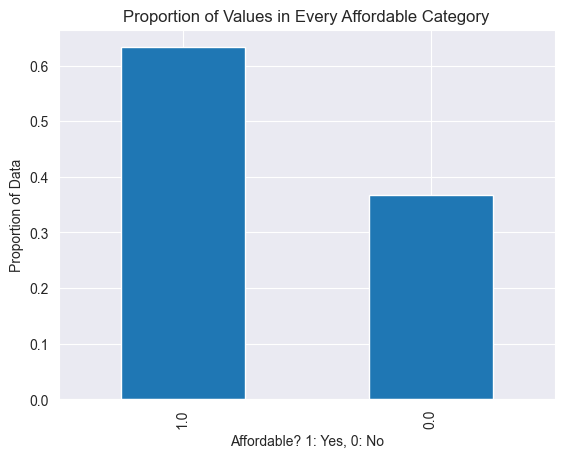

In [33]:
ENCODEDCleanedModel1_df['affordable'].value_counts(normalize=True).plot(kind='bar')
plt.ylabel("Proportion of Data")
plt.xlabel("Affordable? 1: Yes, 0: No")
plt.title("Proportion of Values in Every Affordable Category")
plt.show()

In [34]:
ENCODEDCleanedModel1_df['affordable'].value_counts(normalize=True)

affordable
1.0    0.632691
0.0    0.367309
Name: proportion, dtype: float64

Class Imbalance is present with 63% of data being affordable = 1 and 36.7% of data being affordable = 0. This class imbalance is similar to the raw entire dataset from redfin - cleaning didnt shift class imbalance.

Steps moving forward:
* use Stratify on train test split step to preserve class proportion of 63% / 36.7% making test set representative of real data.
* use class_weight = 'balanced' when training the log reg model to account for class imbalance.

Train and Test Split

In [36]:
#subsetting further to x columns and y columns
ENCODEDCleanedModel1_X = ENCODEDCleanedModel1_df.drop(columns='affordable') #exclude target variable affordable
EncodedCleanedModel1_y = ENCODEDCleanedModel1_df['affordable'] #preserve target variable affordable

In [37]:
#splitting into train and test with stratification to preserve 63%/37% affordability imbalance
X_AffordableTrain, X_AffordableTest, y_AffordableTrain, y_AffordableTest = train_test_split(ENCODEDCleanedModel1_X, EncodedCleanedModel1_y, test_size=0.2, random_state=42, stratify=EncodedCleanedModel1_y)

Checking that stratification was appropriately applied:

In [40]:
#Train Dataset: Seeing count of affordable = 0 and affordable = 1 value - seeing if proportion were preserved
y_AffordableTrain.value_counts(normalize=True)

affordable
1.0    0.632703
0.0    0.367297
Name: proportion, dtype: float64

In [42]:
#Test Dataset: Seeing count of affordable = 0 and affordable = 1 value - seeing if proportion were preserved
y_AffordableTest.value_counts(normalize=True)

affordable
1.0    0.632643
0.0    0.367357
Name: proportion, dtype: float64

Fitting the Train Data using Log Reg Model

In [47]:
#intializing the logistic regression model for predicting affordable variable
affordable_logRegModel = Pipeline([
    ("scale", StandardScaler()), #scales large variables for comparability
    ("model", LogisticRegression(max_iter=2000,class_weight='balanced')) #class_weight = 'balanced' ensures the model trains properly with recognizing minority affordable=0 classes
])

In [48]:
#fit the log reg model on the train data
affordable_logRegModel.fit(X_AffordableTrain, y_AffordableTrain)

Pipeline(steps=[('scale', StandardScaler()),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=2000))])

In [49]:
#model prediction on test data now:
predLogReg_affordable = affordable_logRegModel.predict(X_AffordableTest)
probLogReg_affordable = affordable_logRegModel.predict_proba(X_AffordableTest)[:,1]

In [51]:
#metrics to evaluate model:
scores = {
    "accuracy ": metrics.accuracy_score(y_AffordableTest, predLogReg_affordable),
    "f1" : metrics.f1_score(y_AffordableTest, predLogReg_affordable, zero_division=0),
    "precision" : metrics.precision_score(y_AffordableTest, predLogReg_affordable,zero_division=0),
    "recall" : metrics.recall_score(y_AffordableTest, predLogReg_affordable, zero_division=0),
    "roc-auc" : metrics.roc_auc_score(y_AffordableTest, probLogReg_affordable)
}

,test
accuracy,0.950917
f1,0.960518
precision,0.977916
recall,0.943728
roc-auc,0.992804


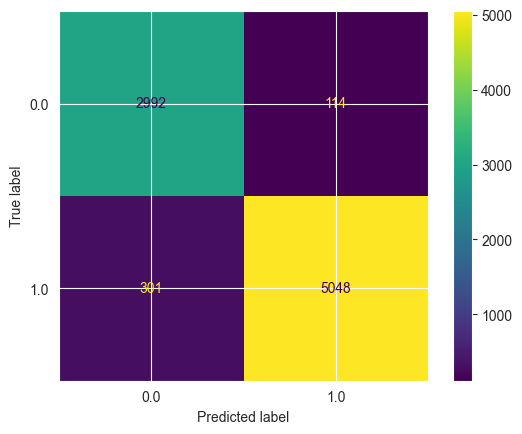

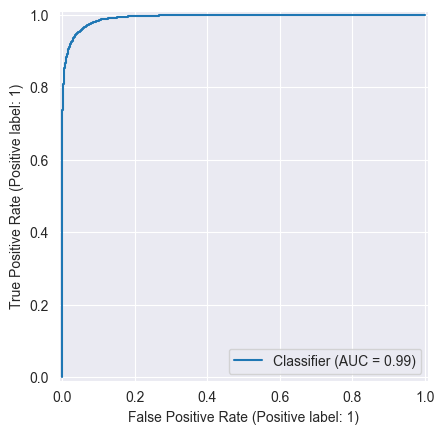

In [52]:
display(pd.Series(scores).to_frame("test"))
metrics.ConfusionMatrixDisplay.from_predictions(y_AffordableTest,predLogReg_affordable)
metrics.RocCurveDisplay.from_predictions(y_AffordableTest,probLogReg_affordable)

In [53]:
print(metrics.confusion_matrix(y_AffordableTest, predLogReg_affordable))

[[2992  114]
 [ 301 5048]]


In [59]:
#Seeing how much performance is attributed to MEDIAN SALE PRICE ($) AND MEDIAN HOUSEHOLD INCOME ($) ALONE to predict affordable = 1 or affordable = 0
X_simple = ENCODEDCleanedModel1_df[['MEDIAN SALE PRICE ($)', 'MEDIAN HOUSEHOLD INCOME ($)']]
y_simple = ENCODEDCleanedModel1_df['affordable']

X_simple_train, X_simple_test, y_simple_train, y_simple_test = train_test_split(X_simple, y_simple, test_size=0.2, random_state=42, stratify=y_simple)

simple_model = Pipeline([("scale", StandardScaler()),("model", LogisticRegression(max_iter=2000, class_weight='balanced'))
])
simple_model.fit(X_simple_train, y_simple_train)
simple_pred = simple_model.predict(X_simple_test)

print("Accuracy with ONLY price + income:", metrics.accuracy_score(y_simple_test, simple_pred))
print("ROC-AUC with ONLY price + income:", metrics.roc_auc_score(y_simple_test, simple_model.predict_proba(X_simple_test)[:,1]))

print("f1 with ONLY price + income:: ", metrics.f1_score(y_simple_test, simple_pred, zero_division=0))
print("precision with ONLY price + income:: ",  metrics.precision_score(y_simple_test, simple_pred,zero_division=0))
print("recall with ONLY price + income:", metrics.recall_score(y_simple_test, simple_pred, zero_division=0))

Accuracy with ONLY price + income: 0.8904790065050266
ROC-AUC with ONLY price + income: 0.9629151184236614
f1 with ONLY price + income::  0.911268685320046
precision with ONLY price + income::  0.9347356005504226
recall with ONLY price + income: 0.8889512058328659


In [65]:
#seeing all coefficients in the model - essentially examining all variables effects on predicting affordability in the log reg model
feature_names = X_AffordableTrain.columns #pulling out column names

affordable_logRegCoefs = affordable_logRegModel.named_steps['model'].coef_[0] #grabbing coefficients from the model
affordable_logRegIntercept = affordable_logRegModel.named_steps['model'].intercept_ #grabbing model intercept

In [69]:
#creating a table with all features and their coefficients, sorted from coefficients with most to least effect (absolute)
affordableLogReg_coefTable = pd.DataFrame({
    'feature': feature_names,
    'coefficient': affordable_logRegCoefs,
}).sort_values('coefficient',key=abs,ascending=False)

In [70]:
affordableLogReg_coefTable

,feature,coefficient
2,MEDIAN SALE PRICE ($),-17.045610
1,MEDIAN HOUSEHOLD INCOME ($),6.818860
0,DOWN PAYMENT PERCENT (%),3.240480
17,Region Identifier_Outside US,0.909242
19,Region Identifier_Southeast,0.746837
14,Region Identifier_Mountain West,0.698418
20,Region Identifier_Southwest,0.372676
18,Region Identifier_PNW,0.282906
15,Region Identifier_Non-Contiguous States,0.279342
16,Region Identifier_Northeast,-0.247545


In [66]:
feature_names

Index(['DOWN PAYMENT PERCENT (%)', 'MEDIAN HOUSEHOLD INCOME ($)',
       'MEDIAN SALE PRICE ($)', 'Month Name_August', 'Month Name_December',
       'Month Name_February', 'Month Name_January', 'Month Name_July',
       'Month Name_June', 'Month Name_March', 'Month Name_May',
       'Month Name_November', 'Month Name_October', 'Month Name_September',
       'Region Identifier_Mountain West',
       'Region Identifier_Non-Contiguous States',
       'Region Identifier_Northeast', 'Region Identifier_Outside US',
       'Region Identifier_PNW', 'Region Identifier_Southeast',
       'Region Identifier_Southwest'],
      dtype='object')

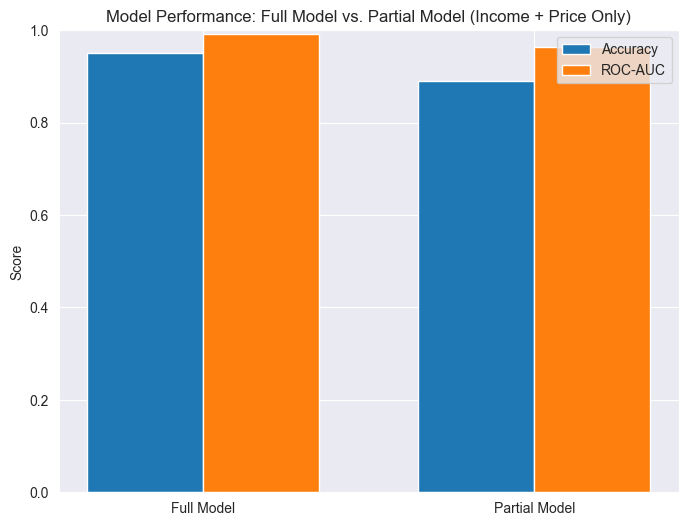

In [75]:
#making 2 bar comparison chart for the presentation:
models = ['Full Model', 'Partial Model']

FullModel_accuracy =  metrics.accuracy_score(y_AffordableTest, predLogReg_affordable)
FullModel_RocAuc = metrics.roc_auc_score(y_AffordableTest, affordable_logRegModel.predict_proba(X_AffordableTest)[:,1])

PartialModel_accuracy = metrics.accuracy_score(y_simple_test, simple_pred)
PartialModel_RocAuc = metrics.roc_auc_score(y_simple_test, simple_model.predict_proba(X_simple_test)[:,1])

accuracy_scores = [FullModel_accuracy, PartialModel_accuracy ]
RocAuc_scores = [FullModel_RocAuc, PartialModel_RocAuc ]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8,6))
ax.bar(x - width/2, accuracy_scores, width, label='Accuracy')
ax.bar(x + width/2, RocAuc_scores, width, label='ROC-AUC')

ax.set_ylabel('Score')
ax.set_title('Model Performance: Full Model vs. Partial Model (Income + Price Only)')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0,1)
ax.legend()
plt.show()

In [76]:
#the scaling worked properly!!
scaler = affordable_logRegModel.named_steps['scale']
print("Means learned from training data:", scaler.mean_[:3])  # first 3 features, e.g. Down Payment %, Income, Price
print("Std devs learned from training data:", scaler.scale_[:3])

Means learned from training data: [1.06989355e+01 1.01727423e+05 3.40868576e+05]
Std devs learned from training data: [6.15843707e+00 2.03986441e+04 1.63940101e+05]


**Model 2: K Means Cluster of States by Affordability Profile**

I will analyze for down payment of 3.5% for all 4 property types. It's the lowest barrier to entry and is commonly used by first time buyers when purchasing their first home. It's the least amount of money to pay upfront too.

Steps to take to prep for K Means Cluster:

1) Filter to 3.5% down payment and one property type.
2) Subset to needed columns (Affordable Listing Share (%), Median Sale Price, Median Household Income, Years to Save Down Payment, State)
3) calculate mean of numerical variables

Step 1: Filtering to 3.5% down payment and Single Family Home Property Type

In [81]:
HomeownerModeling_df['DOWN PAYMENT PERCENT (%)'].unique()

array([ 3.5,  5. , 10. , 15. , 20. ])

In [82]:
HomeownerModeling_df['PROPERTY TYPE'].unique()

array(['Single Family', 'Townhouse', 'Condo/Co-op', 'Starter Home'],
      dtype=object)

In [83]:
#doing single family homes for this analysis
subset_HomeownerModeling_df = HomeownerModeling_df.loc[
    (HomeownerModeling_df['DOWN PAYMENT PERCENT (%)'] == 3.5) &
    (HomeownerModeling_df['PROPERTY TYPE'] == 'Single Family')]

In [84]:
subset_HomeownerModeling_df.head()

,FREQUENCY,PERIOD BEGIN,PERIOD END,REGION NAME,PROPERTY TYPE,INCOME GROUP,DOWN PAYMENT PERCENT (%),INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),...,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,Season,Year-Month,Period Length (Days),affordable,Region Identifier
0,Monthly,2026-06-01,2026-06-30,Alabama,Single Family,Homeowner,3.5,90532.0,-1.49,31.52,...,0.4057,0.0287,-0.0276,0.0130,0.0832,Summer,2026-06,30,0.0,Southeast
1,Monthly,2026-05-01,2026-05-31,Alabama,Single Family,Homeowner,3.5,90652.0,-0.56,31.56,...,0.4212,0.0419,-0.0142,0.0269,0.0091,Spring,2026-05,31,0.0,Southeast
2,Monthly,2026-04-01,2026-04-30,Alabama,Single Family,Homeowner,3.5,88160.0,0.65,30.69,...,0.4302,0.0365,-0.0003,0.0413,0.0217,Spring,2026-04,30,0.0,Southeast
3,Monthly,2026-03-01,2026-03-31,Alabama,Single Family,Homeowner,3.5,86472.0,-1.26,30.11,...,0.4482,0.0405,-0.0133,0.0279,0.0641,Spring,2026-03,31,0.0,Southeast
4,Monthly,2026-02-01,2026-02-28,Alabama,Single Family,Homeowner,3.5,82901.0,-3.96,28.86,...,0.4824,0.0765,-0.0137,0.0274,0.0637,Winter,2026-02,28,1.0,Southeast


In [85]:
subset_HomeownerModeling_df['PROPERTY TYPE'].unique()

array(['Single Family'], dtype=object)

In [86]:
subset_HomeownerModeling_df['DOWN PAYMENT PERCENT (%)'].unique()

array([3.5])

In [89]:
subset_HomeownerModeling_df.columns

Index(['FREQUENCY', 'PERIOD BEGIN', 'PERIOD END', 'REGION NAME',
       'PROPERTY TYPE', 'INCOME GROUP', 'DOWN PAYMENT PERCENT (%)',
       'INCOME REQUIRED ($)', 'INCOME REQUIRED YOY (%)',
       'SHARE OF INCOME ON HOUSING (%)',
       'SHARE OF INCOME ON HOUSING YOY (PPTS)', 'AFFORDABLE LISTING SHARE (%)',
       'AFFORDABLE LISTING SHARE YOY (PPTS)', 'YEARS TO SAVE DOWN PAYMENT',
       'YEARS TO SAVE DOWN PAYMENT YOY (%)', 'MONTHLY HOUSING PAYMENT ($)',
       'MONTHLY MORTGAGE PAYMENT ($)', 'MONTHLY PROPERTY TAX ($)',
       'MONTHLY PROPERTY INSURANCE ($)', 'MONTHLY PMI ($)',
       'DOWN PAYMENT AMOUNT ($)', 'MEDIAN HOUSEHOLD INCOME ($)',
       'MEDIAN SALE PRICE ($)', 'MEDIAN SALE PRICE YOY (%)', 'HOMES SOLD',
       'HOMES SOLD YOY (%)', 'Year', 'Month', 'Month Name', 'Quarter',
       'INCOME REQUIRED YOY (%) Prop', 'SHARE OF INCOME ON HOUSING (%) Prop',
       'SHARE OF INCOME ON HOUSING YOY (PPTS) Prop',
       'AFFORDABLE LISTING SHARE (%) Prop',
       'AFFORDABLE LISTI

In [93]:
subset_HomeownerModeling_df = subset_HomeownerModeling_df[['DOWN PAYMENT PERCENT (%)', 'PROPERTY TYPE', 'AFFORDABLE LISTING SHARE (%)', 'MEDIAN SALE PRICE ($)', 'MEDIAN HOUSEHOLD INCOME ($)', 'YEARS TO SAVE DOWN PAYMENT', 'REGION NAME']]

In [94]:
subset_HomeownerModeling_df.head()

,DOWN PAYMENT PERCENT (%),PROPERTY TYPE,AFFORDABLE LISTING SHARE (%),MEDIAN SALE PRICE ($),MEDIAN HOUSEHOLD INCOME ($),YEARS TO SAVE DOWN PAYMENT,REGION NAME
0,3.5,Single Family,40.57,303787.0,86165,2.47,Alabama
1,3.5,Single Family,42.12,305490.0,86165,2.48,Alabama
2,3.5,Single Family,43.02,299900.0,86165,2.44,Alabama
3,3.5,Single Family,44.82,297976.0,86165,2.42,Alabama
4,3.5,Single Family,48.24,288900.0,86165,2.35,Alabama


In [98]:
state_meanValues_df = subset_HomeownerModeling_df.groupby(['REGION NAME'])[['AFFORDABLE LISTING SHARE (%)', 'MEDIAN SALE PRICE ($)', 'MEDIAN HOUSEHOLD INCOME ($)', 'YEARS TO SAVE DOWN PAYMENT']].mean()

In [99]:
state_meanValues_df

,AFFORDABLE LISTING SHARE (%),MEDIAN SALE PRICE ($),MEDIAN HOUSEHOLD INCOME ($),YEARS TO SAVE DOWN PAYMENT
REGION NAME,,,,
Alabama,39.113333,2.843794e+05,80524.428571,2.473810
Alaska,34.467619,3.974375e+05,114515.428571,2.428571
Arizona,11.741905,4.508411e+05,95912.428571,3.294048
Arkansas,42.190714,2.577058e+05,76805.714286,2.348095
California,14.883095,7.483865e+05,129797.714286,4.036905
Colorado,14.927619,5.773793e+05,119721.428571,3.380476
Columbia,28.015952,1.093785e+06,178171.571429,4.296429
Connecticut,31.811429,4.311337e+05,127529.571429,2.364286
Delaware,25.425714,4.118484e+05,102042.285714,2.826429


In [100]:
print(state_meanValues_df.isna().sum())

AFFORDABLE LISTING SHARE (%)    0
MEDIAN SALE PRICE ($)           0
MEDIAN HOUSEHOLD INCOME ($)     0
YEARS TO SAVE DOWN PAYMENT      0
dtype: int64


next step: scale the 4 variables

In [102]:
#initializing the scaler
scaler = StandardScaler()

In [103]:
scaled_features = scaler.fit_transform(state_meanValues_df) #scales variable values and returns an array in row order

In [104]:
scaled_stateFeature_df = pd.DataFrame(
    scaled_features, #placing scaled features in dataframe
    columns=state_meanValues_df.columns,
    index=state_meanValues_df.index
)

In [105]:
scaled_stateFeature_df.head()

,AFFORDABLE LISTING SHARE (%),MEDIAN SALE PRICE ($),MEDIAN HOUSEHOLD INCOME ($),YEARS TO SAVE DOWN PAYMENT
REGION NAME,,,,
Alabama,0.573612,-0.727533,-1.076233,-0.390430
Alaska,0.244642,-0.072601,0.627932,-0.453646
Arizona,-1.364602,0.236759,-0.304744,0.755769
Arkansas,0.791527,-0.882050,-1.262674,-0.566103
California,-1.142169,1.960404,1.394121,1.793837


In [106]:
#potential k (number of group) values:
kValues = [2,3,4,5,6,7,8]

In [110]:
#finding K of best fit:

maxSilScore = 0
k_maxSilScore = 0
for k in kValues:
    kmeans = KMeans(n_clusters=k, random_state=42,n_init='auto')
    cluster_labels = kmeans.fit_predict(scaled_stateFeature_df)
    silScore = silhouette_score(scaled_stateFeature_df,cluster_labels,metric='euclidean')

    if(silScore > maxSilScore):
        maxSilScore = silScore
        k_maxSilScore = k

print("k of : ", k_maxSilScore, " has max silhouette score: ", maxSilScore)

k of :  2  has max silhouette score:  0.4476651406125725


k = 2 has optimal silhouette score

In [111]:
kmeans_2Clusters= KMeans(n_clusters=2, random_state=42,n_init='auto')
cluster_labels_2 = kmeans_2Clusters.fit_predict(scaled_stateFeature_df)
state_meanValues_df['cluster label k2'] = cluster_labels_2

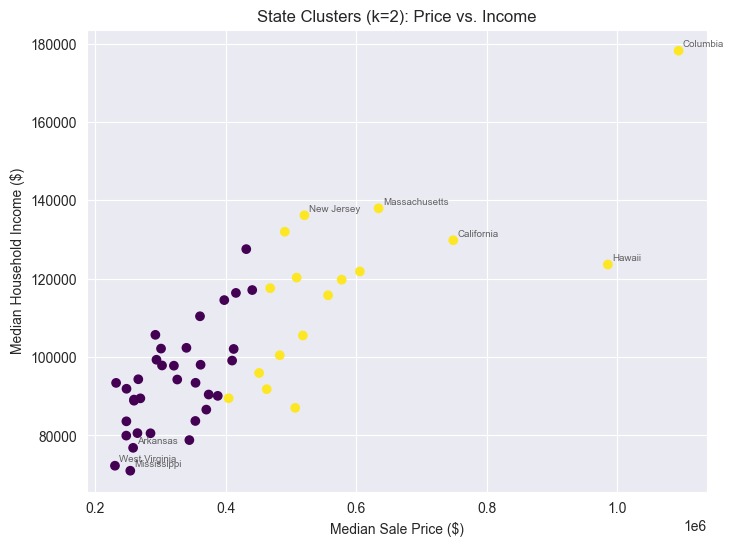

In [120]:
#plotting with 2 dimensions:


key_states = ['Columbia', 'Hawaii', 'California', 'Massachusetts', 'New Jersey','Mississippi', 'West Virginia', 'Arkansas']

plt.figure(figsize=(8,6))
plt.scatter(
    state_meanValues_df['MEDIAN SALE PRICE ($)'],
    state_meanValues_df['MEDIAN HOUSEHOLD INCOME ($)'],
    c = state_meanValues_df['cluster label k2'],
    cmap = 'viridis'
)

for state, row in state_meanValues_df.iterrows():
    if state in key_states:
        plt.annotate(state, (row['MEDIAN SALE PRICE ($)'], row['MEDIAN HOUSEHOLD INCOME ($)']),
                    fontsize=7, alpha=0.7, xytext=(3,3), textcoords='offset points')

plt.xlabel("Median Sale Price ($)")
plt.ylabel('Median Household Income ($)')
plt.title("State Clusters (k=2): Price vs. Income")
plt.show()

In [116]:
print(state_meanValues_df[['MEDIAN SALE PRICE ($)', 'MEDIAN HOUSEHOLD INCOME ($)', 'cluster label k2']].sort_values('cluster label k2'))

                MEDIAN SALE PRICE ($)  MEDIAN HOUSEHOLD INCOME ($)  \
REGION NAME                                                          
Alabama                  2.843794e+05                 80524.428571   
Alaska                   3.974375e+05                114515.428571   
Arkansas                 2.577058e+05                 76805.714286   
Connecticut              4.311337e+05                127529.571429   
Illinois                 2.918342e+05                105648.000000   
Indiana                  2.591083e+05                 89118.142857   
Georgia                  3.611430e+05                 98011.857143   
Delaware                 4.118484e+05                102042.285714   
Iowa                     2.316301e+05                 93381.571429   
Missouri                 2.687913e+05                 89437.428571   
Michigan                 2.591210e+05                 88837.142857   
Minnesota                3.602265e+05                110387.571429   
Maine               

In [118]:
print(state_meanValues_df.sort_values('MEDIAN HOUSEHOLD INCOME ($)', ascending=False).head(10))

               AFFORDABLE LISTING SHARE (%)  MEDIAN SALE PRICE ($)  \
REGION NAME                                                          
Columbia                          28.015952           1.093785e+06   
Massachusetts                     18.714286           6.339781e+05   
New Jersey                        25.868810           5.202473e+05   
Maryland                          34.482619           4.902155e+05   
California                        14.883095           7.483865e+05   
Connecticut                       31.811429           4.311337e+05   
Hawaii                            11.523810           9.853780e+05   
Washington                        13.855714           6.052701e+05   
New Hampshire                     18.387143           5.083829e+05   
Colorado                          14.927619           5.773793e+05   

               MEDIAN HOUSEHOLD INCOME ($)  YEARS TO SAVE DOWN PAYMENT  \
REGION NAME                                                              
Columbia   

In [119]:
print(len(state_meanValues_df))

51


In [121]:
print(state_meanValues_df.loc['Montana'])

AFFORDABLE LISTING SHARE (%)        11.616667
MEDIAN SALE PRICE ($)           506149.071429
MEDIAN HOUSEHOLD INCOME ($)      87010.000000
YEARS TO SAVE DOWN PAYMENT           4.075952
cluster label k2                     1.000000
Name: Montana, dtype: float64


In [122]:
kmeans_4Clusters= KMeans(n_clusters=4, random_state=42,n_init='auto')
cluster_labels_4 = kmeans_4Clusters.fit_predict(scaled_stateFeature_df)
state_meanValues_df['cluster label k4'] = cluster_labels_4

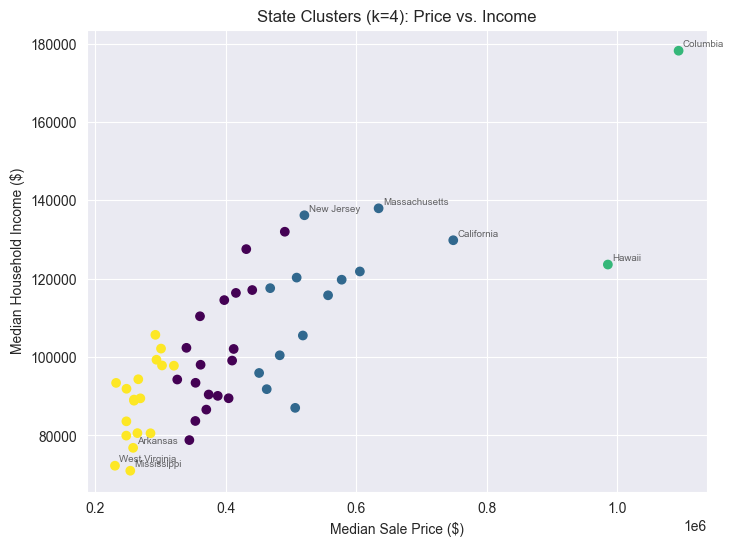

In [123]:
#plotting with 2 dimensions:


key_states = ['Columbia', 'Hawaii', 'California', 'Massachusetts', 'New Jersey','Mississippi', 'West Virginia', 'Arkansas']

plt.figure(figsize=(8,6))
plt.scatter(
    state_meanValues_df['MEDIAN SALE PRICE ($)'],
    state_meanValues_df['MEDIAN HOUSEHOLD INCOME ($)'],
    c = state_meanValues_df['cluster label k4'],
    cmap = 'viridis'
)

for state, row in state_meanValues_df.iterrows():
    if state in key_states:
        plt.annotate(state, (row['MEDIAN SALE PRICE ($)'], row['MEDIAN HOUSEHOLD INCOME ($)']),
                    fontsize=7, alpha=0.7, xytext=(3,3), textcoords='offset points')

plt.xlabel("Median Sale Price ($)")
plt.ylabel('Median Household Income ($)')
plt.title("State Clusters (k=4): Price vs. Income")
plt.show()

In [124]:
silScore_4Clusters = silhouette_score(scaled_stateFeature_df,cluster_labels_4,metric='euclidean')


In [125]:
silScore_4Clusters

np.float64(0.3825310789224814)